# Класифікація тяжкості ДТП — OneVsRest(GBTClassifier)

Ціль: `label = Severity - 1` (класи 0–3). Дані з `classification_data_preparation.ipynb`.

`GBTClassifier` у Spark підтримує лише **бінарну** класифікацію, тому для 4 класів обгортаємо його в `OneVsRest`: навчається 4 бінарні градієнтні бустинги «клас k проти решти». Score класу k — ймовірність позитивного класу (`probability[1]`) відповідної бінарної моделі; ROC-AUC рахуємо за цими score. Пороги оптимізуються як зсуви до чотирьох One-vs-Rest score на validation без використання test.

Інтерпретація: нативні `featureImportances` кожної бінарної моделі та SHAP на деревному сурогаті (`TreeExplainer`).

## Етап 0. Середовище й налаштування

In [2]:
import os, sys, json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.evaluation import Evaluator
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import OneVsRest, GBTClassifier
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import roc_auc_score, roc_curve, f1_score

ROOT = Path.cwd() if (Path.cwd() / 'main.py').exists() else Path.cwd().parent
DATA = ROOT / 'data' / 'processed' / 'classification'
OUT = ROOT / 'data' / 'models'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
TUNE_ROWS = int(os.getenv('TUNE_ROWS','50000'))  # встановити 80000-100000 якщо вистачає ресурсів
TRAIN_FRACTION = float(os.getenv('TRAIN_FRACTION','1'))
SHAP_ROWS = int(os.getenv('SHAP_ROWS','2000'))   # рядків test для пояснення
SURR_ROWS = int(os.getenv('SURR_ROWS','10000'))  # рядків train для навчання сурогата
DRIVER_MEMORY = os.getenv('DRIVER_MEMORY','6g')
CV_FOLDS = 5
CLASSES = [0,1,2,3]
assert (DATA/'metadata.json').exists(), 'Спочатку завершіть classification_data_preparation.ipynb'
os.environ['PYSPARK_PYTHON']=sys.executable
# spark.driver.memory діє лише якщо SparkSession ще не створено: після зміни перезапустіть kernel
spark = (SparkSession.builder.appName('US-Accidents-classification-gbt')
         .master('local[2]').config('spark.driver.memory',DRIVER_MEMORY)
         .config('spark.sql.shuffle.partitions','8')
         .config('spark.driver.maxResultSize','1g').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
print('Spark:',spark.version)

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark: 4.2.1


## Етап 1. Train / valid / test: завантаження, структура, баланс класів

In [3]:
meta = json.loads((DATA/'metadata.json').read_text(encoding='utf-8'))
FEATURES = meta['feature_names']
SAFE = [f'f{i}' for i in range(len(FEATURES))]
def read_split(split):
    src = spark.read.parquet(str(DATA/split))
    cols = [F.col('`'+c.replace('`','``')+'`').cast('double').alias(s)
            for c,s in zip(FEATURES,SAFE)]
    return src.select('ID',F.col('label').cast('double').alias('label'), *cols)
raw={s:read_split(s) for s in ('train','valid','test')}
if TRAIN_FRACTION < 1:
    raw['train']=raw['train'].sampleBy('label',{float(k):TRAIN_FRACTION for k in CLASSES},SEED)
for s,d in raw.items():
    print(s, 'columns:',len(d.columns))
    display(d.select('label',*SAFE[:3]).limit(4).toPandas())

train columns: 246


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,f0,f1,f2
0,1.0,-0.368475,-1.365461,-0.579527
1,2.0,0.538872,0.020882,-0.579527
2,1.0,1.124514,0.419365,-0.579527
3,1.0,-0.014757,0.467713,-0.579527


valid columns: 246


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,f0,f1,f2
0,1.0,-0.240925,0.786081,-0.579527
1,1.0,-0.395562,0.871742,-0.579527
2,2.0,-0.410095,-1.349743,-0.579527
3,1.0,-1.198378,-0.161123,-0.579527


test columns: 246


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,label,f0,f1,f2
0,1.0,-0.082479,0.940955,-0.579527
1,2.0,0.502197,0.289976,-0.579527
2,1.0,-0.441262,-1.332127,-0.579527
3,1.0,0.276899,1.000688,-0.579527


In [4]:
assembler=VectorAssembler(inputCols=SAFE,outputCol='features',handleInvalid='error')
data={s:assembler.transform(df).select('ID','label','features') for s,df in raw.items()}
counts={s:data[s].count() for s in data}
class_dist = {s:{int(r['label']):int(r['count']) for r in d.groupBy('label').count().collect()} for s,d in data.items()}
display(pd.DataFrame(class_dist).fillna(0).astype(int))
weights={float(k):sum(class_dist['train'].values())/(4*max(1,class_dist['train'].get(k,0))) for k in CLASSES}
weight_map=F.create_map(*[x for k,v in weights.items() for x in (F.lit(k),F.lit(float(v)))])
data['train']=data['train'].withColumn('weight',weight_map[F.col('label')].cast('double'))
print('Розміри:',counts,'Ваги:',weights)

,train,valid,test
1,3758419,536450,1073109
0,42475,6015,12064
3,124058,17649,35042
2,864430,123763,246235


Розміри: {'train': 4789382, 'valid': 683877, 'test': 1366450} Ваги: {0.0: 28.189417304296644, 1.0: 0.31857690693879526, 2.0: 1.385127193642053, 3.0: 9.65149768656596}


## Етап 2. Стратифікована вибірка 50–100 тис. та 5-fold CV (macro-F1)

In [5]:
frac = min(1.0, TUNE_ROWS/max(1,counts['train']))
w = Window.partitionBy('label').orderBy(F.rand(SEED))
tune=(data['train'].sampleBy('label',{float(k):frac for k in CLASSES},SEED)
      .withColumn('fold',((F.row_number().over(w)-1)%CV_FOLDS).cast('int'))
      .persist(StorageLevel.MEMORY_AND_DISK))
print('CV rows:',tune.count())

class MacroF1Evaluator(Evaluator):
    def _evaluate(self,pred):
        m=np.zeros((4,4),dtype=float)
        for r in pred.groupBy('label','prediction').count().collect():
            y,p=int(r['label']),int(r['prediction'])
            if y in CLASSES and p in CLASSES:m[y,p]+=r['count']
        tp=np.diag(m); p=m.sum(axis=0); r=m.sum(axis=1)
        den=p+r
        return float(np.mean(np.divide(2*tp,den,out=np.zeros_like(tp),where=den>0)))
    def isLargerBetter(self): return True

evaluator = MacroF1Evaluator()
# base = параметри Spark за замовчуванням (maxIter=20, maxDepth=5, stepSize=0.1, maxBins=32)
gbt=GBTClassifier(featuresCol='features',labelCol='label',seed=SEED)
ovr=OneVsRest(classifier=gbt,featuresCol='features',labelCol='label',predictionCol='prediction')
FAMILIES={'OVR GBTClassifier':ovr}
GRIDS={'OVR GBTClassifier':(ParamGridBuilder()
                            .addGrid(gbt.maxDepth,[4,6])
                            .addGrid(gbt.maxIter,[20,40]).build())}

CV rows: 50248


In [6]:
BEST={}; CV_RESULTS={}
for fam,est in FAMILIES.items():
    print('CV:',fam,flush=True)
    cv=CrossValidator(estimator=est,estimatorParamMaps=GRIDS[fam],evaluator=evaluator,
                      numFolds=CV_FOLDS,foldCol='fold',parallelism=1,seed=SEED)
    fit=cv.fit(tune)
    best_idx=int(np.argmax(fit.avgMetrics))
    BEST[fam]=GRIDS[fam][best_idx]
    t=pd.DataFrame([{p.name:v for p,v in pm.items()} for pm in GRIDS[fam]])
    t['CV macro F1']=fit.avgMetrics
    CV_RESULTS[fam]=t.sort_values('CV macro F1',ascending=False)
    display(CV_RESULTS[fam])

CV: OVR GBTClassifier


,maxDepth,maxIter,CV macro F1
3,6,40,0.619922
2,6,20,0.602172
1,4,40,0.558461
0,4,20,0.514201


## Етап 3. Base / tuned, weighted / unweighted на train

`weighted` — балансування класів через `weightCol` (ваги обчислені на train), яке OneVsRest передає в кожен бінарний `GBTClassifier`.

In [7]:
def cm_and_metrics(pred):
    cm=np.zeros((4,4),dtype=np.int64)
    for r in pred.groupBy('label','prediction').count().collect():
        cm[int(r['label']),int(r['prediction'])]=int(r['count'])
    tp=np.diag(cm).astype(float); support=cm.sum(axis=1); pred_counts=cm.sum(axis=0)
    precision=np.divide(tp,pred_counts,out=np.zeros(4),where=pred_counts>0)
    recall=np.divide(tp,support,out=np.zeros(4),where=support>0)
    f1=np.divide(2*precision*recall,precision+recall,out=np.zeros(4),where=precision+recall>0)
    return {'accuracy':round(float(tp.sum()/max(1,cm.sum())),5),
            'macro F1':round(float(f1.mean()),5),
            'weighted F1':round(float(np.average(f1,weights=support)),5)},cm

MODELS={}; TIMES={}; TRAIN_METRICS={}
for fam,est in FAMILIES.items():
    for variant,params in [('base',{}),('tuned',BEST[fam])]:
        for weighted in (False,True):
            name=f'{fam} {variant} '+('weighted' if weighted else 'unweighted')
            clf=est.getClassifier().copy(params)
            model=OneVsRest(classifier=clf,featuresCol='features',labelCol='label',predictionCol='prediction')
            if weighted:model.setWeightCol('weight')
            print('Fit:',name,flush=True)
            t0=time.time(); MODELS[name]=model.fit(data['train']); TIMES[name]=time.time()-t0
            TRAIN_METRICS[name]=cm_and_metrics(MODELS[name].transform(data['train']))[0]
train_table=pd.DataFrame.from_dict(TRAIN_METRICS,orient='index')
train_table['seconds']=pd.Series(TIMES)
display(train_table.sort_values('macro F1',ascending=False))

Fit: OVR GBTClassifier base unweighted
Fit: OVR GBTClassifier base weighted
Fit: OVR GBTClassifier tuned unweighted
Fit: OVR GBTClassifier tuned weighted


,accuracy,macro F1,weighted F1,seconds
OVR GBTClassifier tuned unweighted,0.89558,0.66082,0.88859,11042.105528
OVR GBTClassifier base unweighted,0.88658,0.60538,0.87658,5247.344279
OVR GBTClassifier tuned weighted,0.77680,0.56523,0.82015,10772.695053
OVR GBTClassifier base weighted,0.75393,0.54044,0.80252,5099.969168


## Етап 4. Validation, вибір лідерів і оптимізація score-offset

In [8]:
VALID_METRICS={}
for name,model in MODELS.items():
    VALID_METRICS[name]=cm_and_metrics(model.transform(data['valid']))[0]
valid_table=pd.DataFrame.from_dict(VALID_METRICS,orient='index')
display(valid_table.sort_values('macro F1',ascending=False))
LEADERS={fam:max((n for n in MODELS if n.startswith(fam+' ')),
                 key=lambda n:VALID_METRICS[n]['macro F1']) for fam in FAMILIES}
print('Лідери:',LEADERS)

def scored_frame(model,frame):
    # s{k} = ймовірність позитивного класу k (probability[1]) бінарного GBT «k проти решти»
    out=frame
    for k,binary_model in enumerate(model.models):
        tmp=binary_model.transform(out)
        src='probability' if 'probability' in tmp.columns else 'rawPrediction'
        out=tmp.withColumn(f's{k}',vector_to_array(F.col(src))[1].cast('double'))
        # Вичистити проміжні колонки, щоб не конфліктували в наступній бінарній моделі
        for c in ('rawPrediction','probability','prediction'):
            if c in out.columns:out=out.drop(c)
    return out

def score_sample(model,split,n=12000):
    frame=data[split].sample(False,min(1.,n/max(1,counts[split])),SEED).limit(n)
    return scored_frame(model,frame).select('label',*[f's{k}' for k in CLASSES]).toPandas()

SAMPLES={}; OFFSETS={}; THRESHOLD_F1={}
for fam,name in LEADERS.items():
    smp=score_sample(MODELS[name],'valid')
    y=smp.label.astype(int).to_numpy(); scores=smp[[f's{k}' for k in CLASSES]].to_numpy()
    scale=max(1e-8,float(np.std(scores)))
    offsets=np.zeros(4)
    best=f1_score(y,np.argmax(scores+offsets,axis=1),average='macro',labels=CLASSES,zero_division=0)
    for sweep in range(3):
        for k in CLASSES:
            candidate=offsets.copy()
            for shift in np.linspace(-.6,.6,13)*scale:
                candidate[k]=offsets[k]+shift
                val=f1_score(y,np.argmax(scores+candidate,axis=1),average='macro',labels=CLASSES,zero_division=0)
                if val>best:best=val; offsets=candidate.copy()
    SAMPLES[fam]=smp; OFFSETS[fam]=offsets; THRESHOLD_F1[fam]=best
    print(fam,'val sampled macro F1:',round(best,5),'offset:',offsets)

,accuracy,macro F1,weighted F1
OVR GBTClassifier tuned unweighted,0.89613,0.66554,0.88943
OVR GBTClassifier base unweighted,0.88731,0.61299,0.87775
OVR GBTClassifier tuned weighted,0.77738,0.56455,0.82072
OVR GBTClassifier base weighted,0.75436,0.53992,0.80294


Лідери: {'OVR GBTClassifier': 'OVR GBTClassifier tuned unweighted'}


c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


OVR GBTClassifier val sampled macro F1: 0.70508 offset: [-0.03663562 -0.32972061  0.03663562  0.10990687]


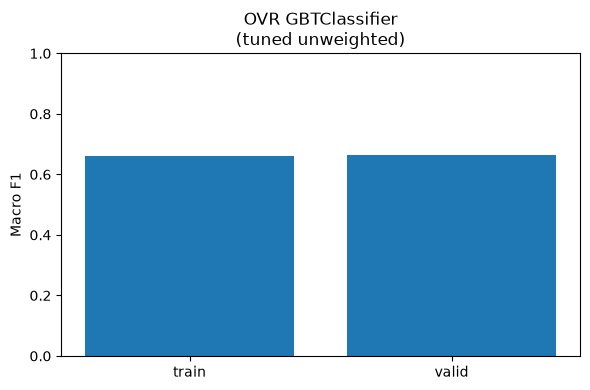

In [9]:
fig,axes=plt.subplots(1,len(LEADERS),figsize=(6*len(LEADERS),4),squeeze=False)
for ax,(fam,name) in zip(axes[0],LEADERS.items()):
    ax.bar(['train','valid'],[TRAIN_METRICS[name]['macro F1'],VALID_METRICS[name]['macro F1']])
    ax.set_ylim(0,1);ax.set_title(f'{fam}\n({name.replace(fam+" ","")})');ax.set_ylabel('Macro F1')
plt.tight_layout();plt.show()

## Етап 5. Test: лідер, матриця помилок, ROC-AUC One-vs-Rest

In [10]:
TEST={}; TEST_CM={}; TEST_SCORE={}; TEST_AUC={}
for fam,name in LEADERS.items():
    model=MODELS[name]
    ds=scored_frame(model,data['test'])
    arr=F.array(*[(F.col(f's{k}')+F.lit(float(OFFSETS[fam][k]))) for k in CLASSES])
    p=(ds.withColumn('_scores',arr)
       .withColumn('prediction',(F.array_position(F.col('_scores'),F.array_max(F.col('_scores')))-1).cast('double')))
    TEST[fam],TEST_CM[fam]=cm_and_metrics(p)
    s=p.sample(False,min(1.,25000/max(1,counts['test'])),SEED).limit(25000)
    small=s.select('label',*[f's{k}' for k in CLASSES]).toPandas()
    yt=small.label.astype(int).to_numpy()
    st=small[[f's{k}' for k in CLASSES]].to_numpy()
    aucs={f'class {k+1}':roc_auc_score((yt==k).astype(int),st[:,k]) if 0<(yt==k).sum()<len(yt) else np.nan
          for k in CLASSES}
    TEST_AUC[fam]=aucs;TEST_SCORE[fam]=(yt,st)
    TEST[fam]['macro ROC-AUC (sample)']=float(np.nanmean(list(aucs.values())))
display(pd.DataFrame.from_dict(TEST,orient='index'))
display(pd.DataFrame(TEST_AUC).T.round(4))

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,accuracy,macro F1,weighted F1,macro ROC-AUC (sample)
OVR GBTClassifier,0.88952,0.69757,0.89018,0.954235


,class 1,class 2,class 3,class 4
OVR GBTClassifier,0.9929,0.9414,0.9607,0.922


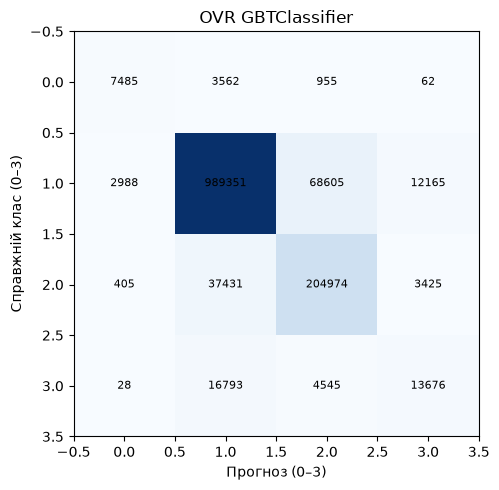

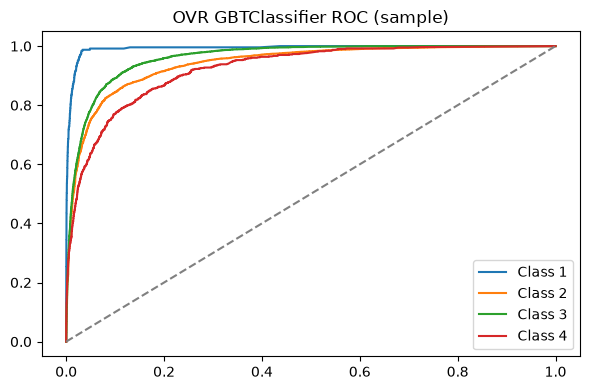

In [11]:
fig,axes=plt.subplots(1,len(TEST_CM),figsize=(6*len(TEST_CM),5),squeeze=False)
for ax,(fam,cm) in zip(axes[0],TEST_CM.items()):
    im=ax.imshow(cm,cmap='Blues')
    ax.set_title(fam);ax.set_xlabel('Прогноз (0–3)');ax.set_ylabel('Справжній клас (0–3)')
    for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center',fontsize=8)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,len(TEST_SCORE),figsize=(6*len(TEST_SCORE),4),squeeze=False)
for ax,(fam,(y,s)) in zip(axes[0],TEST_SCORE.items()):
    for k in CLASSES:
        fpr,tpr,_=roc_curve((y==k).astype(int),s[:,k]);ax.plot(fpr,tpr,label=f'Class {k+1}')
    ax.plot([0,1],[0,1],'--',color='gray');ax.legend();ax.set_title(fam+' ROC (sample)')
plt.tight_layout();plt.show()

## Етап 6. Інтерпретація

### 6.1 Нативні `featureImportances`

Важливість ознак кожної бінарної моделі «клас k проти решти» (нормована сума приростів по деревах, точні значення моделі).

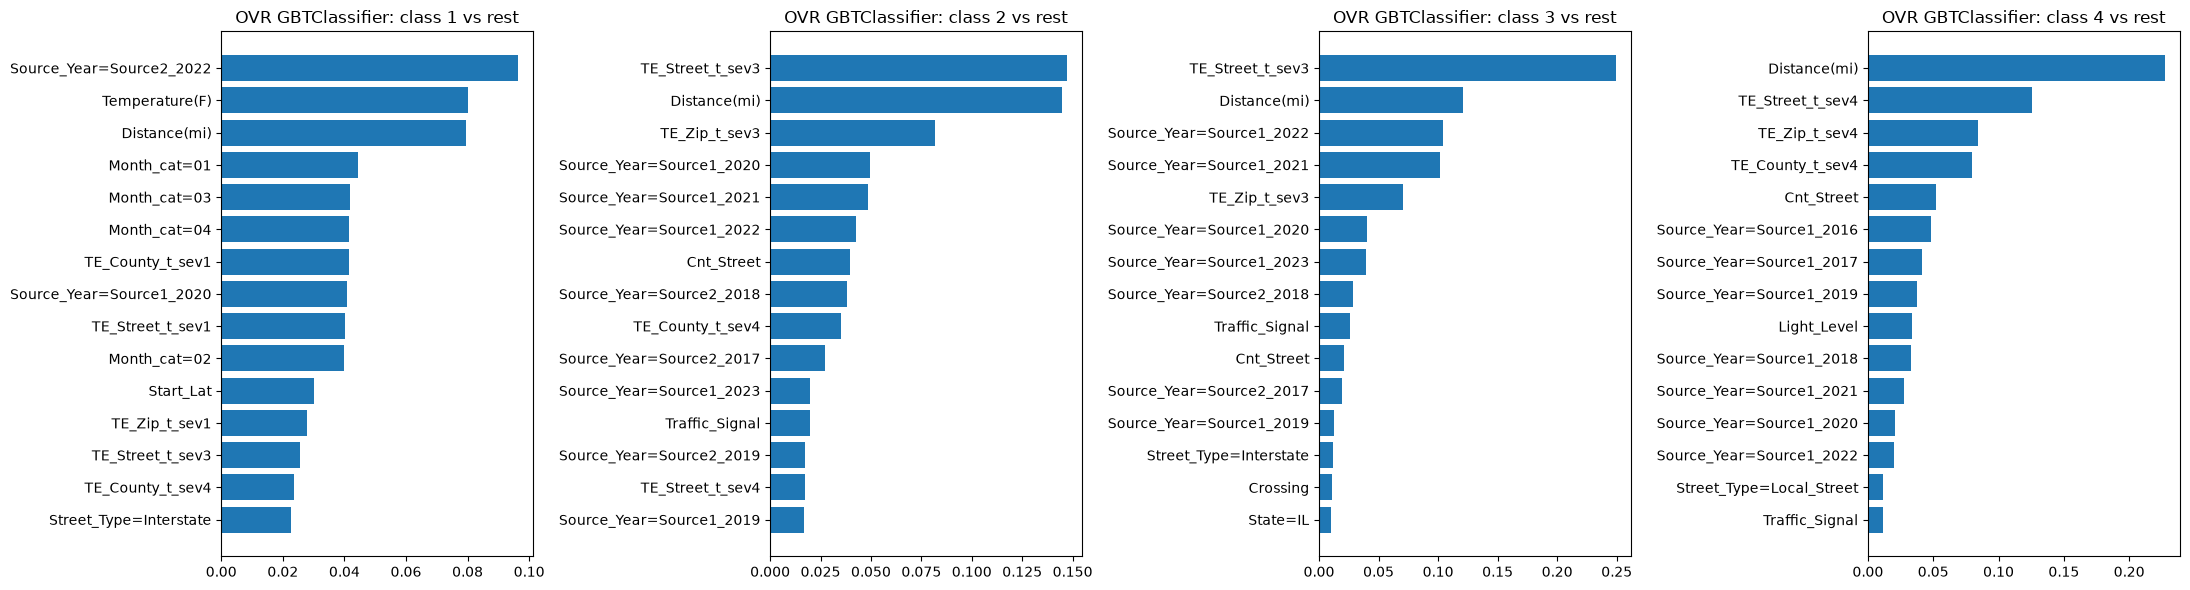

In [12]:
for fam,name in LEADERS.items():
    model=MODELS[name]
    fig,axes=plt.subplots(1,4,figsize=(22,6))
    for k,ax in zip(CLASSES,axes):
        imp=model.models[k].featureImportances.toArray()
        top=np.argsort(-imp)[:15][::-1]
        ax.barh([FEATURES[i] for i in top],imp[top])
        ax.set_title(f'{fam}: class {k+1} vs rest')
    plt.tight_layout();plt.show()

### 6.2 SHAP на деревному сурогаті

Для Spark `GBTClassificationModel` немає готового SHAP-експлейнера. Тому для кожного класу навчаємо **`GradientBoostingRegressor` з sklearn на score** відповідної бінарної моделі (на `SURR_ROWS` рядках train) і пояснюємо його через `shap.TreeExplainer`. Це **SHAP сурогата**, а не точні SHAP-значення Spark-моделі. Fidelity (R²) рахуємо на окремій вибірці test; якщо він низький, інтерпретацію вважати ненадійною.

c:\Users\Admin\Desktop\US-Accidents-spark-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


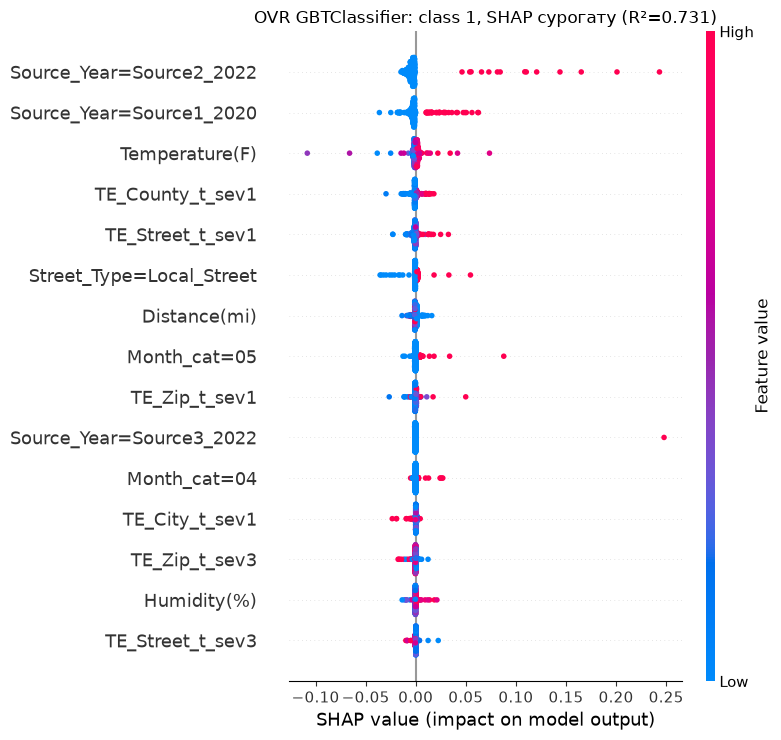

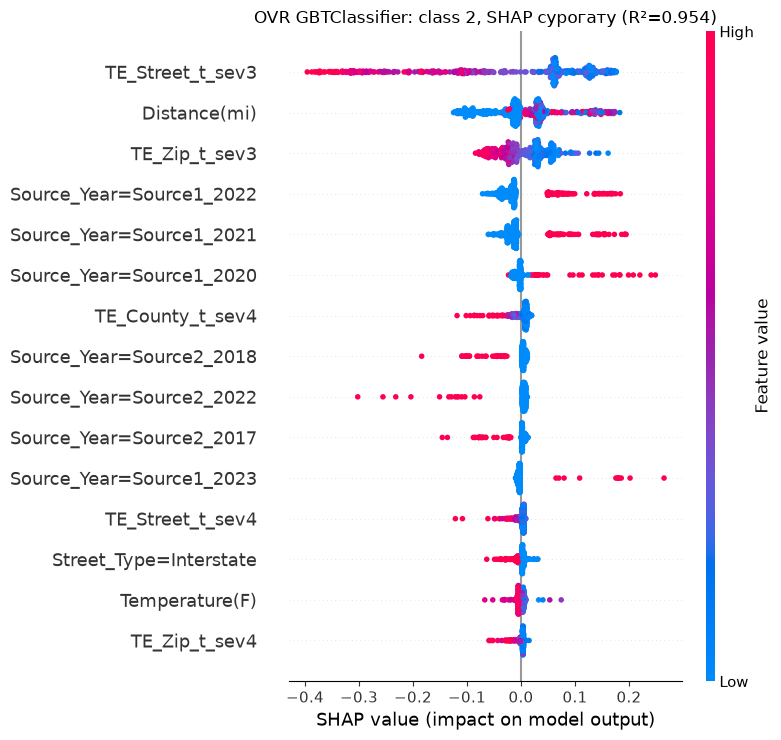

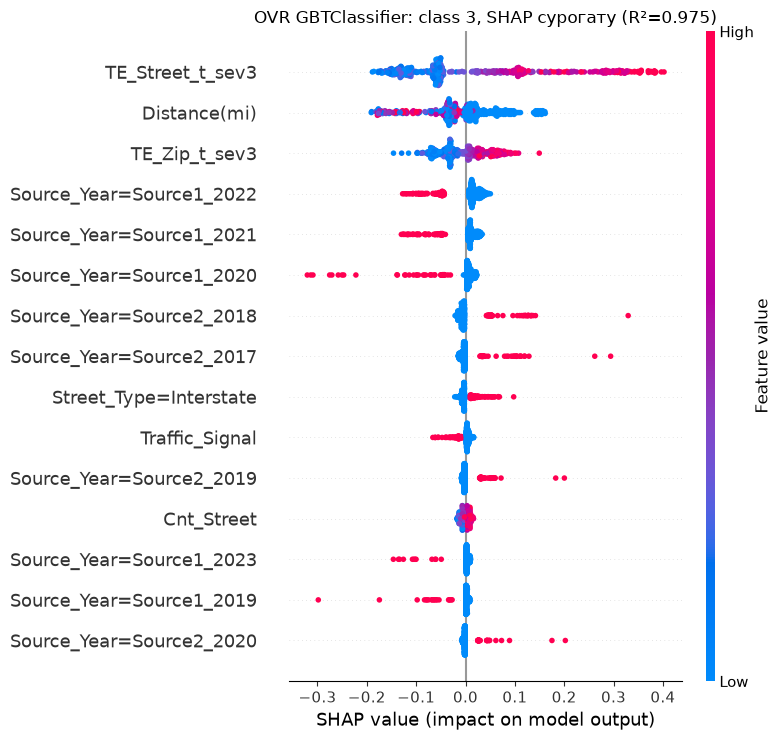

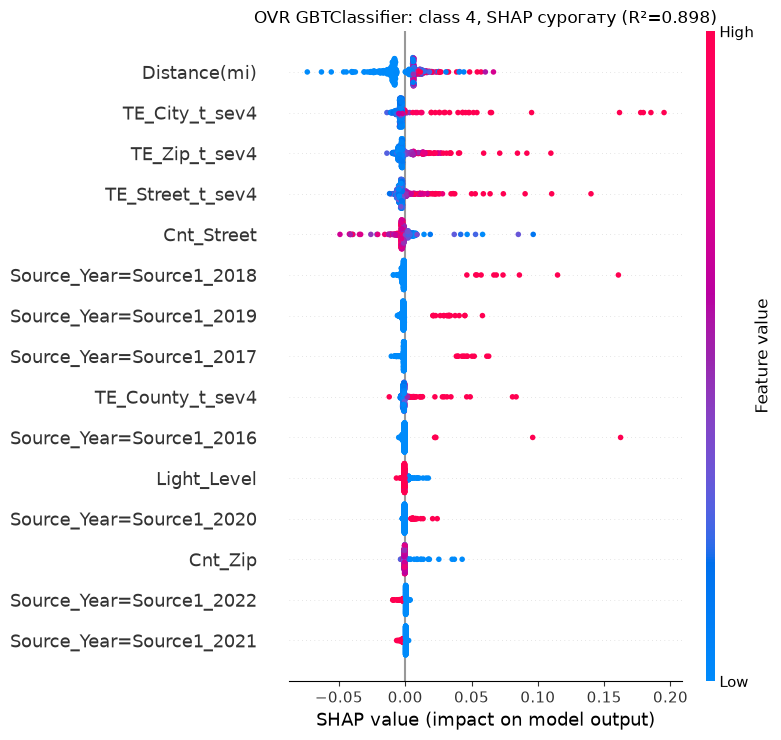

Surrogate fidelity: {'OVR GBTClassifier': {'n_train': 10000, 'n_test': 2000, 'surrogate R2 by class': [0.7306538769039724, 0.9540742698873316, 0.9750800617388783, 0.8977277032088832]}}


In [13]:
import shap
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score

def collect_scores(model,frame):
    rows=scored_frame(model,frame).select('features',*[f's{k}' for k in CLASSES]).collect()
    X=np.vstack([r['features'].toArray() for r in rows])
    S=np.array([[r[f's{k}'] for k in CLASSES] for r in rows])
    return X,S

SHAP_REPORT={}
for fam,name in LEADERS.items():
    model=MODELS[name]
    tr_frac=min(1.,SURR_ROWS/max(1,counts['train']))
    te_frac=min(1.,SHAP_ROWS/max(1,counts['test']))
    train_sub=data['train'].sampleBy('label',{float(k):tr_frac for k in CLASSES},SEED).limit(SURR_ROWS)
    test_sub=data['test'].sampleBy('label',{float(k):te_frac for k in CLASSES},SEED).limit(SHAP_ROWS)
    Xtr,Str=collect_scores(model,train_sub)
    Xte,Ste=collect_scores(model,test_sub)
    if len(Xte)<20:continue
    fidelity=[]
    for k in CLASSES:
        sur=GradientBoostingRegressor(n_estimators=150,max_depth=4,learning_rate=.1,subsample=.8,random_state=SEED)
        sur.fit(Xtr,Str[:,k])
        fidelity.append(float(r2_score(Ste[:,k],sur.predict(Xte))))
        Xe=Xte[:min(500,len(Xte))]
        values=shap.TreeExplainer(sur).shap_values(Xe)
        shap.summary_plot(values,Xe,feature_names=FEATURES,show=False,max_display=15)
        plt.title(f'{fam}: class {k+1}, SHAP сурогату (R²={fidelity[-1]:.3f})');plt.tight_layout();plt.show()
    SHAP_REPORT[fam]={'n_train':len(Xtr),'n_test':len(Xte),'surrogate R2 by class':fidelity}
print('Surrogate fidelity:',SHAP_REPORT)

## Збереження результатів

In [14]:
for fam,name in LEADERS.items():
    MODELS[name].write().overwrite().save(str(OUT/'classification_gbt'))
    print('Model:',OUT/'classification_gbt',f'({name})')
pd.DataFrame.from_dict(TEST,orient='index').to_csv(OUT/'classification_gbt_test_metrics.csv')
pd.DataFrame.from_dict(VALID_METRICS,orient='index').to_csv(OUT/'classification_gbt_valid_metrics.csv')
with open(OUT/'classification_gbt_offsets.json','w',encoding='utf-8') as f:
    json.dump({fam:OFFSETS[fam].tolist() for fam in OFFSETS},f,indent=2)

Py4JJavaError: An error occurred while calling o110863.save.
: java.lang.RuntimeException: java.io.FileNotFoundException: Could not locate Hadoop executable: C:\hadoop\bin\winutils.exe -see https://cwiki.apache.org/confluence/display/HADOOP2/WindowsProblems
	at org.apache.hadoop.util.Shell.getWinUtilsPath(Shell.java:790)
	at org.apache.hadoop.util.Shell.getSetPermissionCommand(Shell.java:299)
	at org.apache.hadoop.util.Shell.getSetPermissionCommand(Shell.java:315)
	at org.apache.hadoop.fs.RawLocalFileSystem.setPermission(RawLocalFileSystem.java:1179)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkOneDirWithMode(RawLocalFileSystem.java:861)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirsWithOptionalPermission(RawLocalFileSystem.java:901)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirs(RawLocalFileSystem.java:873)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirsWithOptionalPermission(RawLocalFileSystem.java:900)
	at org.apache.hadoop.fs.RawLocalFileSystem.mkdirs(RawLocalF